# Laboratory Exercise 1: Food Delivery

City Delivery is a delivery service that brings meals from restaurants across Macedonia to the door. Its pages are a stored snapshot in `data/site`, and the setup serves them from this machine, so every request stays on the local loopback address. The orders are synthetic and describe no real restaurant, courier, or customer.

Answer each request in the cells below it, and add as many cells as you need. The laboratory test asks for values and decisions that your notebook computes, so keep every result visible, run the notebook from top to bottom before you submit it, and make sure it runs on a machine without internet access.

## Setup

The cells in this section are written already. Run them before the tasks.

In [1]:
import json
import re
import threading
from functools import partial
from http.server import SimpleHTTPRequestHandler, ThreadingHTTPServer
from pathlib import Path
from urllib.parse import parse_qs, urljoin, urlparse

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from bs4 import BeautifulSoup, Tag
from playwright.async_api import async_playwright
from scipy import stats
from statsmodels.stats.multitest import multipletests

DATA = Path("data")
# Every random step draws from this generator, so a rerun gives the same result.
rng = np.random.default_rng(2026)

In [2]:
# The course style.
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#1e2a24"]
GROUND, INK, GRID = "#ffffff", "#1e2a24", "#e2e6e4"
plt.rcParams.update(
    {
        "figure.figsize": (8, 4.5),
        "figure.facecolor": GROUND,
        "figure.constrained_layout.use": True,
        "savefig.facecolor": GROUND,
        "savefig.transparent": False,
        "font.family": "sans-serif",
        "font.sans-serif": ["Archivo", "DejaVu Sans"],
        "font.size": 12,
        "text.color": INK,
        "axes.facecolor": GROUND,
        "axes.edgecolor": INK,
        "axes.labelcolor": INK,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.prop_cycle": plt.cycler(color=PALETTE),
        "grid.color": GRID,
        "xtick.color": INK,
        "ytick.color": INK,
        "legend.frameon": False,
        "image.cmap": "cividis",
    }
)
sns.set_palette(PALETTE)

In [3]:
# Every path is a file under the site directory.
class Service(SimpleHTTPRequestHandler):
    extensions_map = {
        **SimpleHTTPRequestHandler.extensions_map,
        ".html": "text/html; charset=utf-8",
    }

    def log_message(self, format: str, *args: object) -> None:
        pass


# Port 0 lets the system choose a free port, so a second running notebook never collides.
server = ThreadingHTTPServer(("127.0.0.1", 0), partial(Service, directory=DATA / "site"))
threading.Thread(target=server.serve_forever, daemon=True).start()
BASE = f"http://127.0.0.1:{server.server_port}/"
BASE

'http://127.0.0.1:46313/'

## Task 1: Collect the Orders

The service lists its delivered orders across several pages, and the first one is `catalogue/page-1.html` under `BASE`. Collect every order into a table named `orders`, with one row per order and these columns:

- `order_id`, the identifier of the order,
- `restaurant`, `cuisine`, and `city`,
- `distance` and `unit`, the distance from the restaurant to the door and the unit it is quoted in, exactly as the order states them,
- `minutes`, the minutes the delivery took,
- `slot`, `weather`, `payment`, and `rating`, the stars out of 5 that the customer gave, and
- `by_restaurant`, which is true when the restaurant delivered the order itself and false when a courier of the service did.

An order that does not state a field has a missing value in that column. Report how many orders the service lists and over how many pages they are spread.

In [4]:
response = requests.get(urljoin(BASE,"catalogue/page-1.html"))
soup = BeautifulSoup(response.text,"lxml")
soup.prettify()[:3000]


'<!DOCTYPE html>\n<html lang="en">\n <head>\n  <meta charset="utf-8"/>\n  <meta content="width=device-width, initial-scale=1" name="viewport"/>\n  <title>\n   Delivered orders, page 1 | City Delivery\n  </title>\n  <link href="../assets/site.css" rel="stylesheet"/>\n </head>\n <body>\n  <header class="site-header">\n   <div class="wrap">\n    <a class="brand" href="../index.html">\n     City Delivery\n    </a>\n    <nav aria-label="Main" class="primary-nav">\n     <a href="../index.html">\n      Home\n     </a>\n     <a aria-current="page" href="../catalogue/page-1.html">\n      Browse\n     </a>\n     <a href="#">\n      Help\n     </a>\n    </nav>\n   </div>\n  </header>\n  <main>\n   <div class="wrap">\n    <h1>\n     Delivered orders\n    </h1>\n    <div class="layout">\n     <section aria-label="Results">\n      <p class="toolbar">\n       192 results, showing 1 to 12\n      </p>\n      <div class="results">\n       <article class="card order" data-id="310069" id="order-310069">\n

In [5]:
COLUMNS = [
    "order_id", "restaurant", "cuisine", "city",
    "distance", "unit", "minutes", "slot",
    "weather", "payment", "rating", "by_restaurant",
]
rows = []
page_url = urljoin(BASE,"catalogue/page-1.html")
visited = set()
pages_count = 0

while page_url and page_url not in visited:
    visited.add(page_url)
    response = requests.get(page_url,timeout = 5)
    if response.status_code != 200:
        break
    pages_count += 1
    soup = BeautifulSoup(response.text,"lxml")
    order_cards = soup.select("article.card.order")

    for order in order_cards:
        row = {column: None for column in COLUMNS}
        row["order_id"] = order.get("data-id")

        restaurant = order.select_one("h2.title a, h2.title")
        if restaurant:
            row["restaurant"] = restaurant.getText(strip = True)
            
        for col in ["cuisine", "city", "slot", "weather", "payment", "rating"]:
            element = order.select_one(f".{col}")
            if element:
                value = element.get_text(" ", strip=True)
                if value not in ("", "-", "—"):
                    row[col] = value
        delivery = order.select_one(".delivery.figure, .delivery")
        if delivery:
            match = re.search(r"(\d+)\s*minutes?", delivery.get_text(" ", strip=True))
            if match:
                row["minutes"] = int(match.group(1))
        summary = order.select_one(".summary")
        if summary:
            match = re.search(r"([\d.]+)\s*(km|mi|m)\b", summary.get_text(" ", strip=True), re.IGNORECASE)
            if match:
                row["distance"] = float(match.group(1))
                row["unit"] = match.group(2)

        courier = order.select_one(".courier.muted, .courier")
        if courier:
            courier_text = courier.get_text(" ", strip=True).lower()
            if "restaurant" in courier_text:
                row["by_restaurant"] = True
            elif "courier" in courier_text or "service" in courier_text or "city delivery" in courier_text:
                row["by_restaurant"] = False

        if row["rating"] is not None:
            match = re.search(r"(\d+(?:\.\d+)?)", str(row["rating"]))
            if match:
                row["rating"] = float(match.group(1))

        rows.append(row)
    next_link = (
        soup.select_one("a[rel='next']")
        or soup.select_one("a.next")
        or soup.select_one("a[aria-label='Next']")
    )
    if next_link and next_link.get("href") and not next_link["href"].startswith("#"):
        page_url = urljoin(page_url, next_link["href"])
    else:
        page_url = None
orders = pd.DataFrame(rows, columns=COLUMNS)
print("Total orders:", len(orders))
print("Total pages:", pages_count)
print(orders.head())



Total orders: 192
Total pages: 16
  order_id    restaurant       cuisine    city  distance unit  minutes  \
0   310069    Salad Bowl         Salad  Skopje       5.0   km     23.0   
1   283894   Pizza House         Pizza  Skopje     650.0    m     30.0   
2   832866     Sushi Bar         Sushi  Skopje     700.0    m      NaN   
3   582431  Home Kitchen   Traditional  Skopje       2.7   km     25.0   
4   662069  Snack Corner  Small plates  Skopje       2.4   km     26.0   

         slot weather payment  rating  by_restaurant  
0  Late night   Clear    Cash     5.0          False  
1       Lunch   Clear    Card     3.0          False  
2       Lunch    Rain    Cash     3.0           True  
3       Lunch    Rain    Card     4.0          False  
4  Late night   Clear    Card     4.0           True  


## Task 2: Add the Receipts

The home page of the service, `index.html` under `BASE`, points to a page of receipts. Collect every receipt the page holds, and add the items, the total, and the tip of each order to `orders`, so that every order appears exactly once. Name the result `df`.

Report how many receipts the page says it holds, how many you collected, and what you did about any receipt that would put an order in `df` more than once.

In [6]:
receipts_url = urljoin(BASE, "receipts.html")
response = requests.get(receipts_url)
response.raise_for_status()

soup = BeautifulSoup(response.text, "lxml")
meta = soup.select_one("#receipts-meta")
print("Receipts information", meta.get_text(" ", strip=True) if meta else "No receipts found")
match = re.search(
    r"const\s+RECEIPTS\s*=\s*(\[.*?\])\s*;",
    response.text,
    re.DOTALL
)
receipts_data = json.loads(match.group(1))
receipts = pd.DataFrame(receipts_data)
receipts.head()
print("Total receipts:", len(receipts))
print("Duplicates:",  receipts["order_id"].duplicated().sum())
receipts = receipts.drop_duplicates(subset="order_id", keep="first")
orders_unique = orders.drop_duplicates(subset="order_id", keep="first")
receipts["order_id"] = receipts["order_id"].astype(str)
df = orders_unique.merge(
    receipts,
    on="order_id",
    how="left",
    validate="one_to_one"
)
print("Total receipts:", len(orders_unique))

Receipts information 
Total receipts: 193
Duplicates: 1
Total receipts: 192


## Task 3: Describe the Orders

Answer each request below from `df`. Support each answer with the numbers that establish it, and with a figure wherever the request asks you to show something.

### 3.1 Column Types

Give every column of `df` a type that matches what it measures. The slots have a natural order, from lunch to late night, and the type of `slot` keeps it.

In [7]:
print(df.dtypes)

print(df["slot"].unique())

df["slot"] = df["slot"].str.strip()

slot_order = [
    "Lunch",
    "Dinner",
    "Late night"
]
df["slot"] = pd.Categorical(
    df["slot"],
    categories=slot_order,
    ordered=True
)

print(df["slot"].dtype)
print(df["slot"].cat.categories)
print(df["slot"].cat.ordered)


order_id             str
restaurant           str
cuisine              str
city                 str
distance         float64
unit                 str
minutes          float64
slot                 str
weather              str
payment              str
rating           float64
by_restaurant       bool
items              int64
total              int64
tip                int64
dtype: object
<StringArray>
['Late night', 'Lunch', 'Dinner']
Length: 3, dtype: str
category
Index(['Lunch', 'Dinner', 'Late night'], dtype='str')
True


### 3.2 What Is Missing

Count the missing values in each column, show where they fall, and find out whether the absence of a value depends on another column.

In [23]:
missing_counts = df.isna().sum().sort_values(ascending=False)
print("Missing values per column:")
print(missing_counts.to_frame(name="missing_count"))
missing_rows = df[df.isna().any(axis=1)]
print("Num of rows with missing values", len(missing_rows))

print(missing_rows)


Missing values per column:
               missing_count
minutes                   42
rating                    24
restaurant                 0
cuisine                    0
city                       0
distance                   0
order_id                   0
unit                       0
slot                       0
weather                    0
payment                    0
by_restaurant              0
items                      0
total                      0
tip                        0
Num of rows with missing values 60
    order_id    restaurant       cuisine      city  distance unit  minutes  \
2     832866     Sushi Bar         Sushi    Skopje     700.0    m      NaN   
10    794180  Snack Corner  Small plates    Skopje       1.4   km      NaN   
17    312377  Burger Bar 7       Burgers    Tetovo       2.3   km     33.0   
23    421364    City Grill         Grill    Bitola       6.4   km      NaN   
28    751240   Pizza House         Pizza    Tetovo       2.2   km     19.0   
29    

### 3.3 Distances in Two Units

Some orders quote the distance in metres and others in kilometres. Compare the quoted distances within each unit, then add a column `distance_km` that states every distance in kilometres.

      count        mean         std    min    25%    50%    75%    max
unit                                                                  
km    162.0    3.230247    1.276013    1.3    2.3    2.9    4.1    8.0
m      30.0  531.666667  201.067553  150.0  362.5  550.0  687.5  900.0


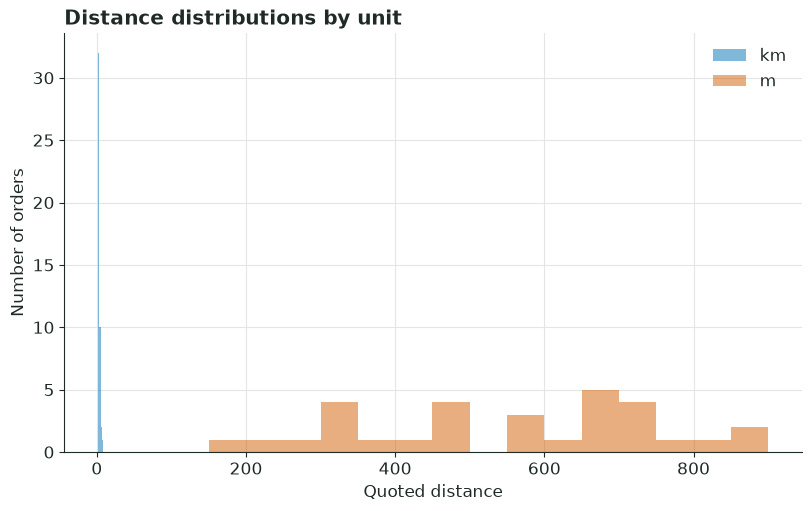

In [8]:
distance_summary = (
    df.groupby("unit")["distance"]
      .describe()
)

print(distance_summary)

import matplotlib.pyplot as plt

units = df["unit"].dropna().unique()

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")

for unit in units:
    values = df.loc[df["unit"] == unit, "distance"].dropna()
    ax.hist(values, bins=15, alpha=0.5, label=unit)

ax.set_xlabel("Quoted distance")
ax.set_ylabel("Number of orders")
ax.set_title("Distance distributions by unit")
ax.legend()

plt.show()

### 3.4 The Delivery Time

Describe the delivery time by its centre, its spread, and the shape of its distribution, and show the distribution. Decide which summary of the centre describes a typical order better.

In [10]:
print(df["minutes"].describe())

print("Mean:", df["minutes"].mean())
print("Median:", df["minutes"].median())
print("Standard deviation:", df["minutes"].std())
print("Variance:", df["minutes"].var())
print("Skewness:", df["minutes"].skew())

q1 = df["minutes"].quantile(0.25)
q3 = df["minutes"].quantile(0.75)

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", q3 - q1)

count    150.000000
mean      29.780000
std       10.283805
min       12.000000
25%       23.000000
50%       27.000000
75%       34.000000
max       72.000000
Name: minutes, dtype: float64
Mean: 29.78
Median: 27.0
Standard deviation: 10.283804952219874
Variance: 105.75664429530201
Skewness: 1.4267454245259108
Q1: 23.0
Q3: 34.0
IQR: 11.0


### 3.5 Delivery Time by Slot

Compare the delivery time across the slots.

In [12]:
slot_summary = (
    df.groupby("slot")["minutes"]
      .agg(["count", "mean", "median", "std", "min", "max"])
      .round(2)
)

print(slot_summary)


            count   mean  median    std   min   max
slot                                               
Lunch          45  28.93    27.0   9.61  12.0  54.0
Dinner         61  30.75    28.0   9.50  16.0  54.0
Late night     44  29.30    26.0  11.99  17.0  72.0


### 3.6 Orders by City

Show how the orders are spread across the cities, and give the share of orders in each city.

In [15]:
city_counts = df["city"].value_counts()


city_share = df["city"].value_counts(normalize=True) * 100


city_summary = pd.DataFrame({
    "orders": city_counts,
    "share_percent": city_share.round(2)
})

print(city_summary)

          orders  share_percent
city                           
Skopje        99          51.56
Tetovo        24          12.50
Kumanovo      22          11.46
Bitola        18           9.38
Ohrid         15           7.81
Prilep        14           7.29


### 3.7 Items and Total

Show how the number of items and the total of an order move together, and measure how strongly they do. Decide whether the relationship is close to a straight line.

Pearson correlation:  0.881
Spearman correlation: 0.869


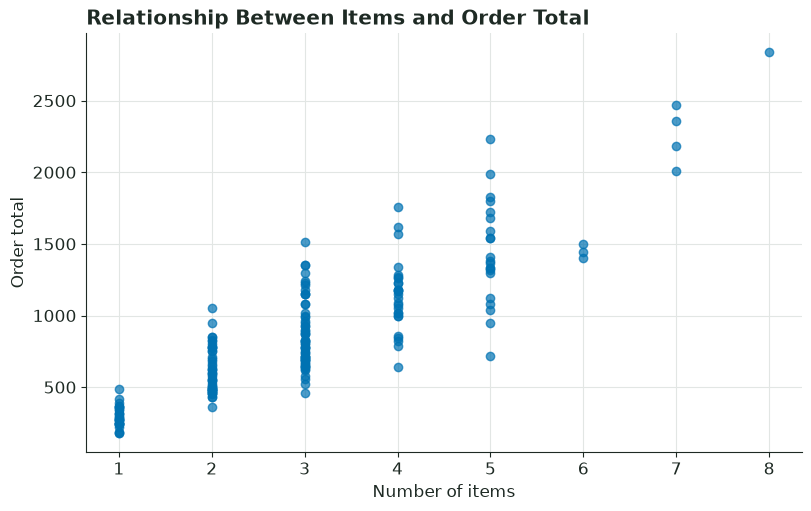

In [23]:
plot_df = df[["items", "total"]].dropna()

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")

ax.scatter(plot_df["items"], plot_df["total"], alpha=0.7)

ax.set_xlabel("Number of items")
ax.set_ylabel("Order total")
ax.set_title("Relationship Between Items and Order Total")

pearson_corr = plot_df["items"].corr(
    plot_df["total"],
    method="pearson"
)

spearman_corr = plot_df["items"].corr(
    plot_df["total"],
    method="spearman"
)

print(f"Pearson correlation:  {pearson_corr:.3f}")
print(f"Spearman correlation: {spearman_corr:.3f}")


### 3.8 Every Pair of Numeric Columns

Show how strongly every pair of numeric columns moves together, measured by the Spearman correlation, and name the pair that moves together most strongly.

In [22]:
numeric_df = df.select_dtypes(include="number")


spearman_corr = numeric_df.corr(method="spearman")


print(spearman_corr.round(3))

upper_triangle = spearman_corr.where(
    np.triu(np.ones(spearman_corr.shape), k=1).astype(bool)
)

pairs = upper_triangle.stack().rename("spearman").reset_index()
pairs.columns = ["column_1", "column_2", "spearman"]


pairs["abs_spearman"] = pairs["spearman"].abs()

pairs = pairs.dropna(subset=["spearman"])

print
(
    pairs.sort_values("abs_spearman", ascending=False).head(10)
)

if not pairs.empty:
    strongest = pairs.loc[pairs["abs_spearman"].idxmax()]

    print("Најсилен пар:", strongest["column_1"], "и", strongest["column_2"])
    print("Spearman correlation:", round(strongest["spearman"], 4))


          distance  minutes  rating  items  total    tip
distance     1.000    0.286  -0.191 -0.018 -0.029  0.009
minutes      0.286    1.000  -0.415 -0.066 -0.036  0.071
rating      -0.191   -0.415   1.000  0.082  0.088 -0.041
items       -0.018   -0.066   0.082  1.000  0.869  0.423
total       -0.029   -0.036   0.088  0.869  1.000  0.463
tip          0.009    0.071  -0.041  0.423  0.463  1.000
Најсилен пар: items и total
Spearman correlation: 0.8691


### 3.9 Delivery Time by City and Slot

Find the combination of city and slot with the highest median delivery time, counting only the combinations with at least three orders that state a delivery time.

In [29]:
city_slot_summary = (
    df.groupby(["city", "slot"])["minutes"]
      .agg(
          order_count="count",
          median_minutes="median"
      )
      .reset_index()
)


eligible_combinations = city_slot_summary[
    city_slot_summary["order_count"] >= 3
].copy()


eligible_combinations = eligible_combinations.sort_values("median_minutes",ascending=False)

print(eligible_combinations)

if not eligible_combinations.empty:
    highest = eligible_combinations.iloc[0]

    print("City:", highest["city"])
    print("Slot:", highest["slot"])
    print("Median delivery time:", highest["median_minutes"], "minutes")
    print("Orders with known delivery time:", highest["order_count"])

        city        slot  order_count  median_minutes
10    Prilep      Dinner            5            35.0
15    Tetovo       Lunch            3            34.0
4   Kumanovo      Dinner            6            33.5
17    Tetovo  Late night            5            32.0
8      Ohrid  Late night            3            32.0
3   Kumanovo       Lunch            8            29.5
16    Tetovo      Dinner            8            29.5
0     Bitola       Lunch            4            28.5
13    Skopje      Dinner           35            28.0
9     Prilep       Lunch            3            27.0
14    Skopje  Late night           22            26.0
7      Ohrid      Dinner            5            26.0
2     Bitola  Late night            6            25.5
6      Ohrid       Lunch            4            25.0
12    Skopje       Lunch           23            24.0
5   Kumanovo  Late night            5            23.0
11    Prilep  Late night            3            17.0
City: Prilep
Slot: Dinner
Me

## Task 4: Delivery Times

Use a significance level of 5 % and a confidence level of 95 % for every decision and every range in this task and the next. For each question, state the decision and give the range beside it. The questions of this task concern the orders that state a delivery time.

### 4.1 The Advertised Time

The home page states an average delivery time. Decide whether the average delivery time of the orders differs from that statement, and give a range for the average delivery time.

In [25]:


advertised_minutes = 30


delivery_times = df["minutes"].dropna().astype(float)

n = len(delivery_times)
sample_mean = delivery_times.mean()
sample_std = delivery_times.std(ddof=1)
standard_error = stats.sem(delivery_times)


t_stat, p_value = stats.ttest_1samp(
    delivery_times,
    popmean=advertised_minutes
)


ci_low, ci_high = stats.t.interval(
    confidence=0.95,
    df=n - 1,
    loc=sample_mean,
    scale=standard_error
)

print(f"Number of orders: {n}")
print(f"Advertised delivery time: {advertised_minutes:.2f} minutes")
print(f"Sample mean: {sample_mean:.2f} minutes")
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value: {p_value:.4f}")
print(f"95% confidence interval: [{ci_low:.2f}, {ci_high:.2f}] minutes")

if p_value < 0.05:
    print("Decision: Reject H0.")
    print("Conclusion: The average delivery time differs significantly "
          "from the advertised time.")
else:
    print("Decision: Fail to reject H0.")
    print("Conclusion: There is insufficient evidence that the average "
          "delivery time differs from the advertised time.")


Number of orders: 150
Advertised delivery time: 30.00 minutes
Sample mean: 29.78 minutes
t-statistic: -0.2620
p-value: 0.7937
95% confidence interval: [28.12, 31.44] minutes
Decision: Fail to reject H0.
Conclusion: There is insufficient evidence that the average delivery time differs from the advertised time.


### 4.2 Rain and Clear Weather

Decide whether the orders delivered in rain and in clear weather differ in their average delivery time, and give a range for the difference, taken as rain minus clear.

In [27]:
weather_df = df.loc[
    df["weather"].isin(["Rain", "Clear"]),
    ["weather", "minutes"]
].dropna()

rain = weather_df.loc[weather_df["weather"] == "Rain", "minutes"]
clear = weather_df.loc[weather_df["weather"] == "Clear", "minutes"]

print("Rain orders:", len(rain))
print("Clear orders:", len(clear))
print(f"Rain mean: {rain.mean():.2f} minutes")
print(f"Clear mean: {clear.mean():.2f} minutes")


difference = rain.mean() - clear.mean()


t_stat, p_value = stats.ttest_ind(
    rain, clear,
    equal_var=False,
    alternative="two-sided"
)


n1, n2 = len(rain), len(clear)
var1, var2 = rain.var(ddof=1), clear.var(ddof=1)

se = np.sqrt(var1 / n1 + var2 / n2)

df_welch = (var1 / n1 + var2 / n2) ** 2 / (
    (var1 / n1) ** 2 / (n1 - 1)
    + (var2 / n2) ** 2 / (n2 - 1)
)

critical_t = stats.t.ppf(0.975, df_welch)

ci_low = difference - critical_t * se
ci_high = difference + critical_t * se

print(f"\nDifference (Rain - Clear): {difference:.2f} minutes")
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value: {p_value:.4f}")
print(f"95% CI for difference: [{ci_low:.2f}, {ci_high:.2f}] minutes")

if p_value < 0.05:
    print("\nDecision: Reject H0.")
    print("Conclusion: The average delivery times differ significantly.")
else:
    print("\nDecision: Fail to reject H0.")
    print("Conclusion: There is insufficient evidence of a difference "
          "in average delivery times.")

Rain orders: 45
Clear orders: 105
Rain mean: 32.78 minutes
Clear mean: 28.50 minutes

Difference (Rain - Clear): 4.28 minutes
t-statistic: 2.1960
p-value: 0.0314
95% CI for difference: [0.39, 8.17] minutes

Decision: Reject H0.
Conclusion: The average delivery times differ significantly.


## Task 5: Slots and Payments

The questions of this task concern all orders.

### 5.1 Payment by Slot

Decide whether the payment method depends on the slot of an order, and give a range for the share of cash payments in each slot, using a percentile bootstrap.

In [33]:
payment_df = df[["slot", "payment"]].dropna().copy()


contingency_table = pd.crosstab(
    payment_df["slot"],
    payment_df["payment"]
)

chi2, p_value, dof, expected = stats.chi2_contingency(
    contingency_table
)

print("Contingency table:")
print(contingency_table)

print(f"\nChi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"p-value: {p_value:.4f}")

alpha = 0.05

if p_value < alpha:
    print("Decision: Reject H0.")
    print("Conclusion: Payment method and slot are significantly associated.")
else:
    print("Decision: Fail to reject H0.")
    print("Conclusion: There is insufficient evidence of an association "
          "between payment method and slot.")


expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

print("\nExpected frequencies:")
print(expected_df.round(2))



rng = np.random.default_rng(42)
B = 10_000
confidence_level = 0.95
cash_results = []

for slot_name, group in payment_df.groupby("slot", observed=True):
    payments = group["payment"].to_numpy()
    n = len(payments)


    cash_share = np.mean(payments == "Cash")

    bootstrap_shares = np.empty(B)

    for b in range(B):
        sample = rng.choice(payments, size=n, replace=True)
        bootstrap_shares[b] = np.mean(sample == "Cash")

  
    lower = np.percentile(
        bootstrap_shares,
        100 * (1 - confidence_level) / 2
    )
    upper = np.percentile(
        bootstrap_shares,
        100 * (1 + confidence_level) / 2
    )

    cash_results.append({
        "slot": slot_name,
        "n": n,
        "cash_count": np.sum(payments == "Cash"),
        "cash_share": cash_share,
        "ci_lower": lower,
        "ci_upper": upper
    })

cash_ci = pd.DataFrame(cash_results)


for col in ["cash_share", "ci_lower", "ci_upper"]:
    cash_ci[col] = 100 * cash_ci[col]

print("\nCash payment share and 95% percentile bootstrap CI by slot:")
print(cash_ci.round(2).to_string(index=False))

Contingency table:
payment     Card  Cash
slot                  
Lunch         49     7
Dinner        57    22
Late night    34    23

Chi-square statistic: 11.1349
Degrees of freedom: 2
p-value: 0.0038
Decision: Reject H0.
Conclusion: Payment method and slot are significantly associated.

Expected frequencies:
payment      Card   Cash
slot                    
Lunch       40.83  15.17
Dinner      57.60  21.40
Late night  41.56  15.44

Cash payment share and 95% percentile bootstrap CI by slot:
      slot  n  cash_count  cash_share  ci_lower  ci_upper
     Lunch 56           7       12.50      5.36     21.43
    Dinner 79          22       27.85     18.99     37.97
Late night 57          23       40.35     28.07     52.63


### 5.2 The Mix of Slots

The home page states how the orders divide among the slots. Decide whether the orders match that statement, and give a range for the share of late-night orders, using a percentile bootstrap.

In [34]:
# All orders with a known slot
slots = df["slot"].dropna()

# Observed distribution
observed = slots.value_counts().sort_index()

print("Observed counts:")
print(observed)
print("\nObserved shares (%):")
print((observed / observed.sum() * 100).round(2))

# Replace these example placeholders with the exact homepage proportions.
# The keys must match the slot labels in your dataset.
advertised_shares = {
    "Dinner": ...,
    "Late night": ...,
    "Lunch": ...
}

# Validate the advertised distribution
advertised_shares = pd.Series(advertised_shares, dtype=float)

if not np.isclose(advertised_shares.sum(), 1.0):
    raise ValueError("Advertised proportions must sum to 1.0.")

if set(observed.index) != set(advertised_shares.index):
    raise ValueError(
        f"Slot categories differ. Observed: {list(observed.index)}; "
        f"advertised: {list(advertised_shares.index)}"
    )

# Align proportions to the observed order
advertised_shares = advertised_shares.reindex(observed.index)

expected = advertised_shares.to_numpy() * observed.sum()

# Chi-square goodness-of-fit test
chi2, p_value = stats.chisquare(
    f_obs=observed.to_numpy(),
    f_exp=expected
)

print(f"\nChi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {len(observed) - 1}")
print(f"p-value: {p_value:.4f}")

if p_value < 0.05:
    print("Decision: Reject H0.")
    print("Conclusion: The observed slot distribution differs "
          "significantly from the advertised distribution.")
else:
    print("Decision: Fail to reject H0.")
    print("Conclusion: There is insufficient evidence that the "
          "observed distribution differs from the advertised distribution.")


# Percentile bootstrap 95% CI for Late night share
rng = np.random.default_rng(42)
B = 10_000

slot_array = slots.to_numpy()
n = len(slot_array)

late_night_share = np.mean(slot_array == "Late night")

bootstrap_shares = np.empty(B)

for b in range(B):
    sample = rng.choice(slot_array, size=n, replace=True)
    bootstrap_shares[b] = np.mean(sample == "Late night")

ci_low, ci_high = np.percentile(bootstrap_shares, [2.5, 97.5])

print(f"\nLate-night orders: {np.sum(slot_array == 'Late night')}")
print(f"Total orders with known slot: {n}")
print(f"Late-night share: {late_night_share * 100:.2f}%")
print(
    "95% percentile bootstrap CI: "
    f"[{ci_low * 100:.2f}%, {ci_high * 100:.2f}%]"
)


Observed counts:
slot
Lunch         56
Dinner        79
Late night    57
Name: count, dtype: int64

Observed shares (%):
slot
Lunch         29.17
Dinner        41.15
Late night    29.69
Name: count, dtype: float64


TypeError: float() argument must be a string or a real number, not 'ellipsis'

In [20]:
server.shutdown()